# Lab 1 - Feed-Forward Neural Networks for Intrusion Detection

We use a single-hidden-layer FFNN to classify four traffic classes. Task 1 covers our preprocessing; We completed Task 2A with our first scaled classifier (validation macro-F1 0.9234). Tasks 2B-6 are still pending.

- [NOTES.md](NOTES.md): our answers to the assignment questions.
- [LOGBOOK.md](LOGBOOK.md): our experiments and results.

We run this notebook from Lab_01, using `Materiale/dataset_lab_1.csv`.

## Task 1 - Preprocessing [PDF §5]

### Imports

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


### 1.1 - Raw samples and class balance

We start with 31,507 flows, 16 numerical features and four classes. We inspect their counts before cleaning to assess imbalance and guide our split.

In [34]:
# Load the dataset

df = pd.read_csv("Materiale/dataset_lab_1.csv")

print(df['Label'])

df['Label'].value_counts()





0             Benign
1             Benign
2             Benign
3             Benign
4             Benign
            ...     
31502    Brute Force
31503    Brute Force
31504    Brute Force
31505    Brute Force
31506    Brute Force
Name: Label, Length: 31507, dtype: str


Label
Benign         20000
DoS Hulk        5000
PortScan        5000
Brute Force     1507
Name: count, dtype: int64

### 1.2 - Cleaning

We remove missing values, exact duplicates, infinities and selected negative values, in that order. Our row counts are 31,507 -> 31,487 -> 29,393 -> 29,386 -> 29,384. We discuss the removed rows, class changes and limitations in NOTES.md.

(29384, 17)
0
0
Label
Benign         19240
PortScan        4849
DoS Hulk        3868
Brute Force     1427
Name: count, dtype: int64
0


Text(0.5, 1.0, 'Distribution of Flow Duration')

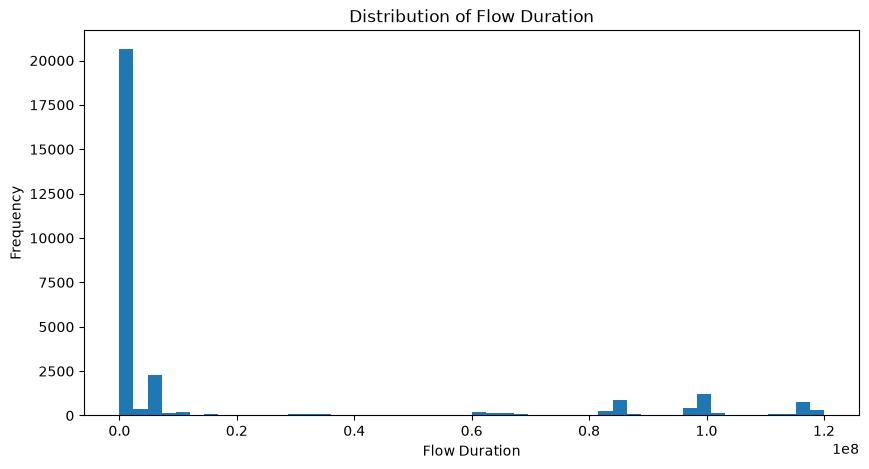

In [35]:
#CLEANING dropna, drop duplicates, drop inf, drop negative values

df = df.dropna()
df = df.drop_duplicates()
df["Label"].value_counts()
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()
cols_idx = [0, 1, 2, 3, 4, 7, 8, 9, 10, 11, 12, 14, 15]

cols = df.columns[cols_idx]

df = df[(df[cols] >= 0).all(axis=1)].copy()



print(df.shape)
print(df.isna().sum().sum())
print(df.duplicated().sum())
print(df["Label"].value_counts())
print(np.isinf(df.select_dtypes(include=np.number)).sum().sum())

# Plotting the distribution of Flow Duration
plt.figure(figsize=(10, 5))

plt.hist(df["Flow Duration"], bins=50)

plt.xlabel("Flow Duration")
plt.ylabel("Frequency")
plt.title("Distribution of Flow Duration")


### 1.3 - Stratified train/validation/test split and label encoding

We use a 70/15/15 split with random_state=42: 20,568 / 4,408 / 4,408 samples. We fit the label encoder on training and reuse it unchanged. In Task 2A, we also seed model initialization and batch shuffling.

In [36]:
#SPLITTED DATA + INTUITION REAGRDING CLASS CLASSIFICATION
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Label"])
Y = df["Label"]


print(df.shape)

# 70% train, 30% temporaneo
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    Y,
    test_size=0.30,
    stratify=Y,#important to keep the same distribution of classes in train and test
    random_state=42
)

# Divide il 30% in 15% validation e 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)
print(X_train.shape)
print(X_test.shape)
print(X_val.shape)

#   Encoding the labels for training, validation, and test sets
#   metto a posto le label per il training, validation e test set

# Label Encoder da Numpy array OCIOOOO
label_encoder = LabelEncoder() 

y_train = label_encoder.fit_transform(y_train)# ocio solo fit su train
y_val = label_encoder.transform(y_val)
y_test = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)
print(label_encoder.transform(label_encoder.classes_))


(29384, 17)
(20568, 16)
(4408, 16)
(4408, 16)
Classes: ['Benign' 'Brute Force' 'DoS Hulk' 'PortScan']
[0 1 2 3]


### 1.4 - Training-only exploratory statistics

We examine feature variance and a one-vs-rest Fisher-like score. We treat the score as an exploratory heuristic; it does not establish which class our FFNN will find hardest.

In [37]:
## Considering the dataset is imbalanced, we can analyze the variance 
## of each feature and apply Fisher's criterion to evaluate the discriminative
## power of each feature for classification.

# STATS TO UNDERSTAND THE DATASET

#variance by feature
variances = X_train.var().sort_values(ascending=False)
print(variances)

# Fisher's ish Criterion
print("\nFisher's Criterion")
scores = {}

for label in np.unique(y_train):

    X_class = X_train[y_train == label]
    X_rest  = X_train[y_train != label]

    mean_class = X_class.mean()
    mean_rest = X_rest.mean()

    var_class = X_class.var()
    var_rest = X_rest.var()

    fisher = (mean_class - mean_rest)**2 / (
        var_class + var_rest + 1e-9
    )

    scores[label] = fisher.mean()

scores = pd.Series(scores).sort_values()

print("0 = Benign, 1 = Brute Force, 2 = DoS Hulk, 3 = PortScan")
print(scores, "\n\nThe higher the score, the more discriminative the feature is for classification.")

Flow Duration             1.317755e+15
Flow Bytes/s              6.975741e+14
Fwd IAT Std               1.500167e+14
Flow IAT Mean             1.903953e+13
Flow Packets/s            3.648223e+10
Destination Port          3.104833e+08
Bwd Packet Length Max     4.038559e+06
Bwd Packet Length Mean    3.843754e+05
Fwd Packet Length Max     2.327037e+05
Packet Length Mean        8.741098e+04
Fwd Packet Length Mean    1.335118e+04
Subflow Fwd Packets       1.354483e+03
Total Fwd Packets         1.354483e+03
Down/Up Ratio             2.752730e-01
SYN Flag Count            3.890614e-02
Fwd PSH Flags             3.890614e-02
dtype: float64

Fisher's Criterion
0 = Benign, 1 = Brute Force, 2 = DoS Hulk, 3 = PortScan
0    0.092924
1    0.142394
3    0.170629
2    1.046245
dtype: float64 

The higher the score, the more discriminative the feature is for classification.


### 1.5 - Class proportions across our partitions

In [38]:
# Proporzioni
print("\nTrain")

print(pd.Series(y_train).value_counts(normalize=True))

print("\nValidation")
print(pd.Series(y_val).value_counts(normalize=True))

print("\nTest")
print(pd.Series(y_test) .value_counts(normalize=True))


Train
0    0.654755
3    0.165014
2    0.131661
1    0.048571
Name: proportion, dtype: float64

Validation
0    0.654719
3    0.165154
2    0.131579
1    0.048548
Name: proportion, dtype: float64

Test
0    0.654946
3    0.164927
2    0.131579
1    0.048548
Name: proportion, dtype: float64


### 1.6 - StandardScaler

We fit the scaler on training only and reuse it unchanged on validation/test. We use these standardized inputs for Task 2A to address the large feature-scale differences.

In [39]:
# Standardization of the dataset SCALER

from sklearn.preprocessing import StandardScaler

scaler_std = StandardScaler()

X_train_std = scaler_std.fit_transform(X_train)
X_val_std = scaler_std.transform(X_val)
X_test_std = scaler_std.transform(X_test)

### 1.7 - Candidate B: log1p(Flow Duration) + StandardScaler

We also apply log1p to Flow Duration before scaling. We have not trained models to compare the two transformations yet, so we cannot claim a classification improvement.

In [40]:

## LOG MIGLIORA LA DISITRIBUZIONE, EVENTUALI DROWBACK ?????
## LOG + SCALER (NON USATO ATTUALMENTE)

import numpy as np
from sklearn.preprocessing import StandardScaler

X_train_log = X_train.copy()
X_val_log = X_val.copy()
X_test_log = X_test.copy()

X_train_log["Flow Duration"] = np.log1p(X_train_log["Flow Duration"])
X_val_log["Flow Duration"] = np.log1p(X_val_log["Flow Duration"])
X_test_log["Flow Duration"] = np.log1p(X_test_log["Flow Duration"])

scaler_log = StandardScaler()

X_train_log_scaled = scaler_log.fit_transform(X_train_log)
X_val_log_scaled = scaler_log.transform(X_val_log)
X_test_log_scaled = scaler_log.transform(X_test_log)

### 1.8 - Visual comparison of scaling candidates

We compare the training Flow Duration histograms. Our Task 2A baseline uses StandardScaler; log1p remains an exploratory alternative that we have not compared through training.

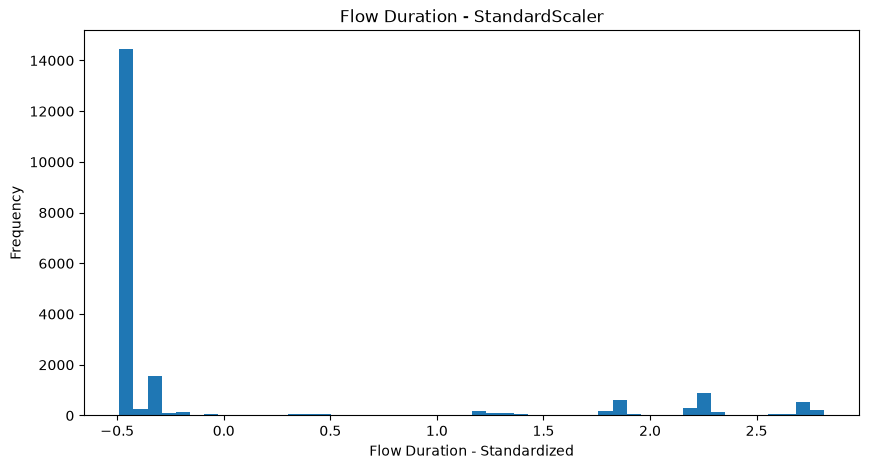

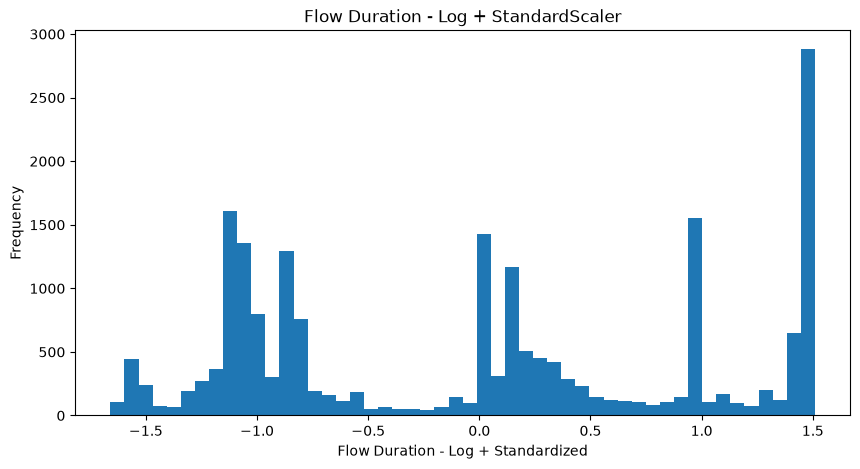

In [41]:
# Plotting the distribution of Flow Duration after 
# Standardization and Log + Standardization

import matplotlib.pyplot as plt

flow_idx = X_train.columns.get_loc("Flow Duration")

plt.figure(figsize=(10, 5))
plt.hist(X_train_std[:, flow_idx], bins=50)
plt.xlabel("Flow Duration - Standardized")
plt.ylabel("Frequency")
plt.title("Flow Duration - StandardScaler")
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(X_train_log_scaled[:, flow_idx], bins=50)
plt.xlabel("Flow Duration - Log + Standardized")
plt.ylabel("Frequency")
plt.title("Flow Duration - Log + StandardScaler")
plt.show()

## Task 2A - Minimal working classifier [PDF §6.1]

### Our hypothesis before training

We expect **Brute Force** to be hardest because it has only 999 training samples (4.86%). We expect **DoS Hulk** to be easier because its exploratory Fisher-like score is highest (1.046 versus 0.093-0.171 for the others). Benign may also be difficult because its score is lowest, despite its larger support. These scores are only clues; we will check the per-class validation results.

### Our choices

We use one hidden layer with 64 ReLU units, four output logits, unweighted cross-entropy, AdamW (lr=5e-4, weight_decay=0.01) and batches of 64. This is a small nonlinear starting point; we keep the loss unweighted to establish our reference model. StandardScaler uses training-only statistics. We use CPU and seed 42 for initialization and batch shuffling.

We train for at most 100 epochs, stopping after 20 epochs without a validation-loss reduction of at least 1e-4. We retain the lowest validation-loss weights and restore them before reporting validation metrics. We do not evaluate test in this task.

In [ ]:
import copy
import random
import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import classification_report, accuracy_score, f1_score

SEED = 42
HIDDEN_SIZE = 64
BATCH_SIZE = 64
LEARNING_RATE = 5e-4
#WEIGHT_DECAY = 0.01
MAX_EPOCHS = 200 #staring 100
PATIENCE = 20
MIN_DELTA = 0.5e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
device = torch.device("cpu")
print(f"Device: {device}; seed: {SEED}")

Device: cpu; seed: 42


### Model and data

We convert our standardized training/validation arrays to float32 tensors. We shuffle training batches only and keep the same class encoding throughout.

In [43]:
class FFNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        return self.fc2(self.relu(self.fc1(x)))


train_dataset = TensorDataset(
    torch.tensor(X_train_std, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long),
)
validation_dataset = TensorDataset(
    torch.tensor(X_val_std, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long),
)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)
validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
)

model = FFNN(X_train_std.shape[1], HIDDEN_SIZE, len(label_encoder.classes_)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
)
print(model)
print(f"Train samples: {len(train_dataset)}; validation samples: {len(validation_dataset)}")

FFNN(
  (fc1): Linear(in_features=16, out_features=64, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=64, out_features=4, bias=True)
)
Train samples: 20568; validation samples: 4408


### Training and early stopping

We average cross-entropy over samples for both partitions. Validation runs without gradient updates. We save every new minimum validation loss; the 1e-4 threshold controls only the patience counter, so even smaller improvements can still provide our best checkpoint.

In [44]:
train_losses, val_losses = [], []
best_val_loss = float("inf")
patience_reference = float("inf")
best_state = None
best_epoch = 0
epochs_without_improvement = 0
training_start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(y_batch)
    train_loss /= len(train_dataset)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in validation_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            loss = criterion(model(X_batch), y_batch)
            val_loss += loss.item() * len(y_batch)
    val_loss /= len(validation_dataset)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())

    if val_loss < patience_reference - MIN_DELTA:
        patience_reference = val_loss
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    print(f"Epoch {epoch:3d} | train CE {train_loss:.5f} | val CE {val_loss:.5f}")
    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

training_seconds = time.perf_counter() - training_start
model.load_state_dict(best_state)
model.eval()
print(f"Restored epoch {best_epoch}: val CE={best_val_loss:.5f}")
print(f"Training + epoch validation: {training_seconds:.2f} s")

Epoch   1 | train CE 0.74733 | val CE 0.49031
Epoch   2 | train CE 0.40398 | val CE 0.34131
Epoch   3 | train CE 0.31045 | val CE 0.28211
Epoch   4 | train CE 0.26708 | val CE 0.26156
Epoch   5 | train CE 0.24384 | val CE 0.23353
Epoch   6 | train CE 0.22834 | val CE 0.22120
Epoch   7 | train CE 0.21710 | val CE 0.21154
Epoch   8 | train CE 0.20794 | val CE 0.20431
Epoch   9 | train CE 0.20040 | val CE 0.19660
Epoch  10 | train CE 0.19387 | val CE 0.19063
Epoch  11 | train CE 0.18793 | val CE 0.18552
Epoch  12 | train CE 0.18327 | val CE 0.18029
Epoch  13 | train CE 0.17885 | val CE 0.17647
Epoch  14 | train CE 0.17543 | val CE 0.17367
Epoch  15 | train CE 0.17235 | val CE 0.17071
Epoch  16 | train CE 0.16946 | val CE 0.16936
Epoch  17 | train CE 0.16713 | val CE 0.16746
Epoch  18 | train CE 0.16523 | val CE 0.16496
Epoch  19 | train CE 0.16338 | val CE 0.16400
Epoch  20 | train CE 0.16188 | val CE 0.16250
Epoch  21 | train CE 0.15990 | val CE 0.16216
Epoch  22 | train CE 0.15872 | val

### Training/validation loss curves

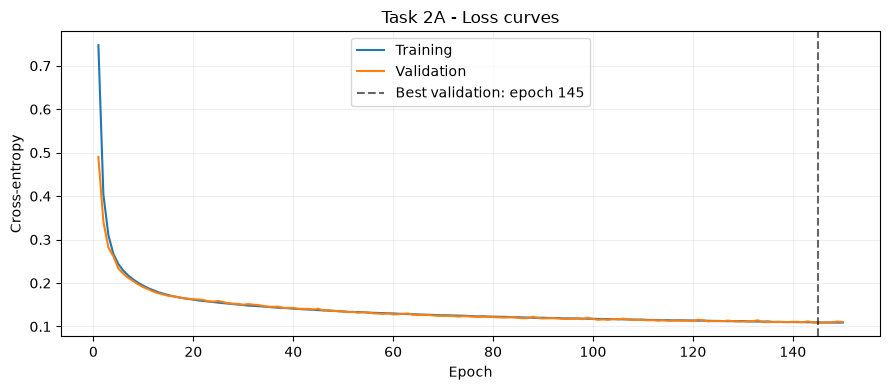

In [45]:
epochs = np.arange(1, len(train_losses) + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs, train_losses, label="Training")
ax.plot(epochs, val_losses, label="Validation")
ax.axvline(best_epoch, color="black", linestyle="--", alpha=0.6,
           label=f"Best validation: epoch {best_epoch}")
ax.set(xlabel="Epoch", ylabel="Cross-entropy", title="Task 2A - Loss curves")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

### Validation classification report

We evaluate the restored model, using validation only. We report precision, recall and F1 for every class, alongside accuracy and macro-F1.

In [46]:
val_predictions = []
restored_val_loss = 0.0
with torch.no_grad():
    for X_batch, y_batch in validation_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model(X_batch)
        restored_val_loss += criterion(logits, y_batch).item() * len(y_batch)
        val_predictions.extend(logits.argmax(dim=1).cpu().tolist())
restored_val_loss /= len(validation_dataset)

class_names = label_encoder.classes_.tolist()
class_ids = list(range(len(class_names)))
val_report = classification_report(
    y_val, val_predictions, labels=class_ids, target_names=class_names,
    output_dict=True, zero_division=0,
)
val_accuracy = accuracy_score(y_val, val_predictions)
val_macro_f1 = f1_score(y_val, val_predictions, labels=class_ids, average="macro")
print(classification_report(
    y_val, val_predictions, labels=class_ids, target_names=class_names,
    digits=4, zero_division=0,
))
print(f"Validation accuracy: {val_accuracy:.4f}; macro-F1: {val_macro_f1:.4f}")
assert np.isclose(restored_val_loss, best_val_loss, rtol=1e-6, atol=1e-8)

              precision    recall  f1-score   support

      Benign     0.9663    0.9740    0.9701      2886
 Brute Force     0.8089    0.9299    0.8652       214
    DoS Hulk     0.9907    0.9207    0.9544       580
    PortScan     0.9496    0.9313    0.9404       728

    accuracy                         0.9578      4408
   macro avg     0.9289    0.9390    0.9325      4408
weighted avg     0.9591    0.9578    0.9581      4408

Validation accuracy: 0.9578; macro-F1: 0.9325


### Our interpretation

**Best model.** We restore epoch 98, which has the lowest validation cross-entropy (0.11698). We use validation loss rather than the last epoch to select our weights. We reached the 100-epoch limit; early stopping did not trigger.

**Convergence.** Our training/validation losses decrease from 0.7473/0.4903 at epoch 1 to 0.1176/0.1174 at epoch 100. The curves stay close and flatten substantially, with no sustained validation increase suggesting overfitting. Validation still improves slowly near the end, so we do not claim complete convergence.

**Hardest classes.** Brute Force has the lowest F1 (0.8450), supporting our prediction in terms of F1. Its recall is 0.9299 (199/214 detected), but precision is only 0.7743: 58 of its 257 predictions are false positives. Its main weakness here is precision, not uniquely low recall; DoS Hulk has slightly lower recall (0.9259).

DoS Hulk has strong precision (0.9711) and F1 (0.9479), but Benign has the highest F1 (0.9656). Our separability heuristic therefore did not correctly rank every class. Benign's low exploratory score did not translate into the weakest classification performance. PortScan has F1 0.9351.

Overall validation accuracy is 0.9519 and macro-F1 is 0.9234. This is one seeded split/run; we have not measured variation across seeds or test performance. Training plus per-epoch validation took 26.55 s on CPU.

## Task 2B - Fundamentals [PDF §6.2]

We have not started this comparison. After completing 2A, we will compare raw inputs (S1), too-high LR (S2) and too-low LR (S3), changing one fundamental at a time. We will record our expected curves before each run, then explain the observed failure mechanisms and rank their severity. Our interrupted L1-001 attempt is not a completed controlled S1 experiment.

## Task 2C - Locked baseline [PDF §6.3]

We still need to finalize our baseline, produce validation/test classification reports and assess the generalization gap. We will compare activations on validation and keep test out of our selection process.

## Task 3 - Destination Port bias [PDF §7]

We have not started this task. We will verify the port association, record our expected Brute Force recall change for the TEST-only port 80 -> 8080 counterfactual, and evaluate our fixed baseline without retraining. We will then remove Destination Port from the original data, redo cleaning/split/scaling and compare class counts. We still need to explain any class collapse and justify our deduplication decision. We will use port-free data for the remaining tasks.

## Task 4 - Rare class and weighted loss [PDF §8]

We have not trained a port-free baseline or compared weighted and unweighted cross-entropy yet. We will compute weights from training labels only, record our expected accuracy/macro-F1 trade-off before training, and interpret our per-class results afterwards.

## Task 5 - Hyperparameters [PDF §9]

We still need to allocate approximately 10 runs across 5A-5D: 2-3 deeper candidates, three batch sizes with training times, and an optimizer/LR comparison involving SGD, momentum SGD and AdamW. We will select our best model on validation, compare it with our Task 4 baseline on test and assess whether its improvement justifies the run cost.

## Task 6 - Optimizations [PDF §10]

We have not started this task. Our initial port-free network will have hidden widths 256/128/64/32/16, ReLU, cross-entropy, AdamW lr=5e-4, batch size 128 and about 150-200 epochs. We will explicitly set weight_decay=0 and omit early stopping for this first run. Within approximately six runs, we will assess overfitting, try a smaller network or early stopping first, then evaluate weight decay, dropout and batch normalization one change at a time. We will compare our final model with the Task 4 baseline on test and discuss performance per unit of effort.